# **E G P A**
## **Estimation of Gaussian Process Algorithm**

EGPA is specially suited to solve optimization
problems where decision variables represent a vector
of amplitudes of a discretized function $Z =
f(X) = (f(x_1), f(x_2), ..., f(x_N))$ defined over grid
$X = [x_1, x_2, ..., x_N]$. This function could be
the solution to a given equation or differential equation,
subject, for instance, to constraints imposed
at particular grid points, such as $x_A$ or $x_B$, of
the form $f(x_A) = A$, or constraints on its derivatives,
e.g., $f'(x_B) = B$.

The algorithm follows the scheme of an EDA, but the probabilistic model updated at every iteration is a Gaussian Process. The population at
each generation is composed of many candidate solutions
like f(X) which are sampled from a GP. The best solutions, according to the cost function to be optimized, are used to update the kernel hyperparameters (lenght scale, vertical scale). The new candidate solutions are sampled from the updated GP. This steps are repeated until a convergence criterion is reached.

To test the algorithm we will solve some instances of the Schrödinger equation. The problems below and specially the plots give a lot of insights about the algorithm behaviour!!


### **Solving the Schrödinger Equation with optimization algorithms**

The problem is converted into an optimization problem by discretizing the wavefunction $\Psi(x)$. Each candidate solution is represented by a vector with $n$ elements to be chosen (the discretization); each element represents the amplitude of the wavefunction at a given point:
$$
\Psi(x)\longrightarrow (\Psi(x_1), \Psi(x_2), \ldots, \Psi(x_n)),
$$
bearing in mind that the wavefunction must be normalized:
$$
\int |\Psi(x)|^2\,dx = 1.
$$

The Schrödinger equation is
$$
\hat{H}\lvert\Psi\rangle = E\lvert\Psi\rangle
\quad\longrightarrow\quad
\left(-\frac{\hbar^2}{2m}\frac{d^2}{dx^2}+V(x)\right)\Psi(x)=E\Psi(x).
$$

Once the wavefunction is discretized, the second derivative can be approximated by
$$
\frac{d^2}{dx^2}\Psi(x_n)=
\frac{\Psi(x_{n-1})+\Psi(x_{n+1})-2\Psi(x_n)}{\Delta x^2},
$$
where $\Delta x=x_i-x_{i-1}$ is the spacing of the $x$-coordinate, which will be taken to be constant.


#### **Optimization function based on the expected value of $E$**

Several objective functions are proposed, following different papers. In all of them, an initial guess for the energy $E$ is required. It can be set to zero because the ground-state energy level will be obtained first.
Following *Direct solution of Schrödinger equation by genetic algorithm: test cases* by Saha et al., one possible choice for the optimization function is
$$
Z=\left[\frac{\langle\Psi|\hat{H}|\Psi\rangle}
{\langle\Psi|\Psi\rangle}-E_l\right]^2,
$$
where $E_l$ is a lower bound on the energy. The integrals in the numerator (the expected value of the energy) and denominator are replaced by quadrature sums to integrate the function numerically. The wavefunction is partitioned into $n_{\max}$ pieces. The integration element is $L/n_{\max}$. Thus,
$$
\langle\Psi|\hat{H}|\Psi\rangle =
-\frac{\hbar^2}{2m}\frac{n_{\max}}{L}
\sum_n \Psi(x_n)
\left[\Psi(x_{n-1})+\Psi(x_{n+1})-2\Psi(x_n)\right] + \frac{L}{n_{\max}}\sum_n\Psi(x_n)V(x_n)\Psi(x_n) ,
$$
and
$$
\langle\Psi|\Psi\rangle
=\int\Psi(x)\Psi^*(x)\,dx
=\Delta x\sum_n\Psi(x_n)^2
=\frac{L}{n_{\max}}\sum_n\Psi(x_n)^2.
$$

The optimization function Z can be exponentiated to $F=e^{-Z}$.

**Excited states**

To obtain the following energy levels, it is sufficient to modify the optimization functions by adding a term that sequentially enforces orthogonality between states, $\langle\Psi|\Phi\rangle = 0$. We have already obtained the *ground state* $|\Psi\rangle$ and its energy.

We add a term to the optimization function:

$$
\beta |\langle\Psi|\Phi\rangle|^2
$$

For a function based on the expected energy, this would become:

$$
Z = \left[\frac{\langle\Phi|\hat{H}|\Phi\rangle}{\langle\Phi|\Phi\rangle} - E_l\right]^2 + \beta |\langle\Psi|\Phi\rangle|^2
$$

Where $|\Psi\rangle$ is the previously calculated ground state, $\beta$ is a penalty factor with appropriate dimensions, and we leave the target energy at its previous value.

### **One-dimensional infinite well**

We will solve the one-dimensional problem of a particle of mass $m$ confined to a box of length $L$. The potential is defined as
$$
V(x)=
\begin{cases}
0, & 0<x<L,\\
\infty, & \text{elsewhere}.
\end{cases}
$$

This problem has the analytical solutions
$$
\Psi_n(x)=\sqrt{\frac{2}{L}}\sin\left(\frac{n\pi x}{L}\right),
\qquad
E_n=n^2\frac{h^2}{8L^2m},
\qquad n=1,2,3,\ldots
$$


In [1]:
import sys
import os
# Get the absolute path of the main directory
main_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
# Add the main directory to sys.path
sys.path.append(main_dir)
from OptFunctions.oneDwellfunctions import *
#from EDAspy.optimization import UMDAc
from EGPA import *
from utils import _parallel_apply_along_axis
import warnings
warnings.filterwarnings("ignore")

In [2]:
L=5
n_variables = 51
X_grid_well = np.linspace(start=0, stop=L, num=n_variables).reshape(-1,1) #para que sean n_variables filas y 1 columna
#Ahora definimos las observaciones que hemos hecho de la función. En este caso son las condiciones de contorno del problema
#Los datos que conocemos son las amplitudes en x=0 x=5 que son 0
X_train = X_grid_well[[0,-1]]
Y_train = np.linspace(start=0, stop=0, num=2).reshape(-1,1) #Para que sea 2D array
params = {'L':L}

In [3]:
def Psi_n(n):
    return((2/L)**0.5*np.sin(n*np.pi*np.linspace(0, L, n_variables)/L))

In [4]:
Gaussian = EGPA(size_gen=500, grid_X=X_grid_well, max_iter=200, dead_iter=20, alpha=0.1, elite_factor=0.05, init_kernels=5 ,parallelize=True, init_data=(X_train, Y_train), analysis_mode=True)
egparesultground = Gaussian.minimize(oneD_wellExpE, params, exp_from = 2, output_runtime=True)

IT:  0 	Best cost:  0.03969357218549497
IT:  1 	Best cost:  -0.9618044123107206
IT:  2 	Best cost:  -0.9618044123107206
IT:  3 	Best cost:  -0.9618044123107206
IT:  4 	Best cost:  -0.9618044123107206
IT:  5 	Best cost:  -0.9618044123107206
IT:  6 	Best cost:  -0.9618044123107206
IT:  7 	Best cost:  -0.9618044123107206
IT:  8 	Best cost:  -0.9618044123107206
IT:  9 	Best cost:  -0.9618044123107206
IT:  10 	Best cost:  -0.9618044123107206
IT:  11 	Best cost:  -0.9618044123107206
IT:  12 	Best cost:  -0.9618044123107206
IT:  13 	Best cost:  -0.9618044123107206
IT:  14 	Best cost:  -0.9618044123107206
IT:  15 	Best cost:  -0.9618044123107206
IT:  16 	Best cost:  -0.9618044123107206
IT:  17 	Best cost:  -0.9618044123107206
IT:  18 	Best cost:  -0.9618044123107206
IT:  19 	Best cost:  -0.9618044123107206
IT:  20 	Best cost:  -0.9618044123107206
	NFEVALS = 11000 F = -0.9618044123107206
	X = [-8.45149042e-09  4.00084135e-02  7.96319019e-02  1.18762351e-01
  1.57289935e-01  1.95103273e-01  2.32

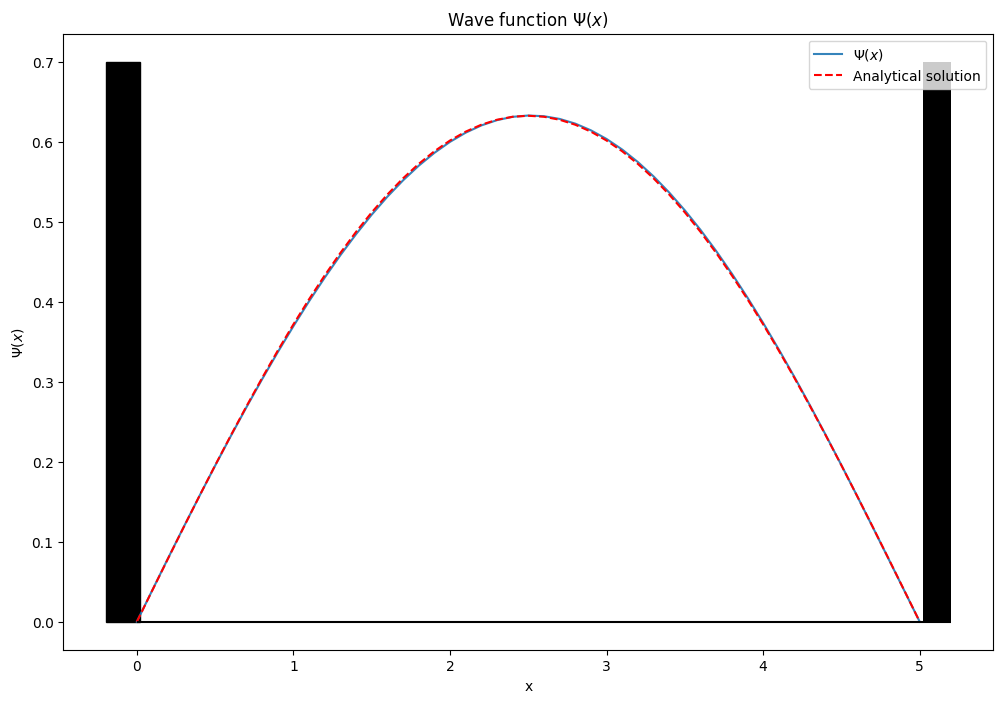

In [5]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 8))

plt.plot(np.linspace(0, 5, n_variables),egparesultground.data[-1,0,:-1], '-', label='$\Psi(x)$', alpha=0.9)
plt.plot(np.linspace(0, 5, n_variables), Psi_n(1), 'r--', label='Analytical solution')
plt.gca().set_title('Wave function $\Psi(x)$')
plt.xlabel('x')
plt.gca().set_ylabel(r'$\Psi(x)$')
plt.legend(loc = 'upper right')
# Define the vertices of the rectangle
x = [-0.2, -0.2, 0.02, 0.02]
x2 = [5.02, 5.02, 5.2, 5.2]
y = [0, 0.7, 0.7, 0]
# Fill the area defined by the vertices
plt.fill(x, y, color='black')
plt.fill(x2, y, 'black')
plt.hlines(y=0, xmin=0, xmax=5.2, colors='k');

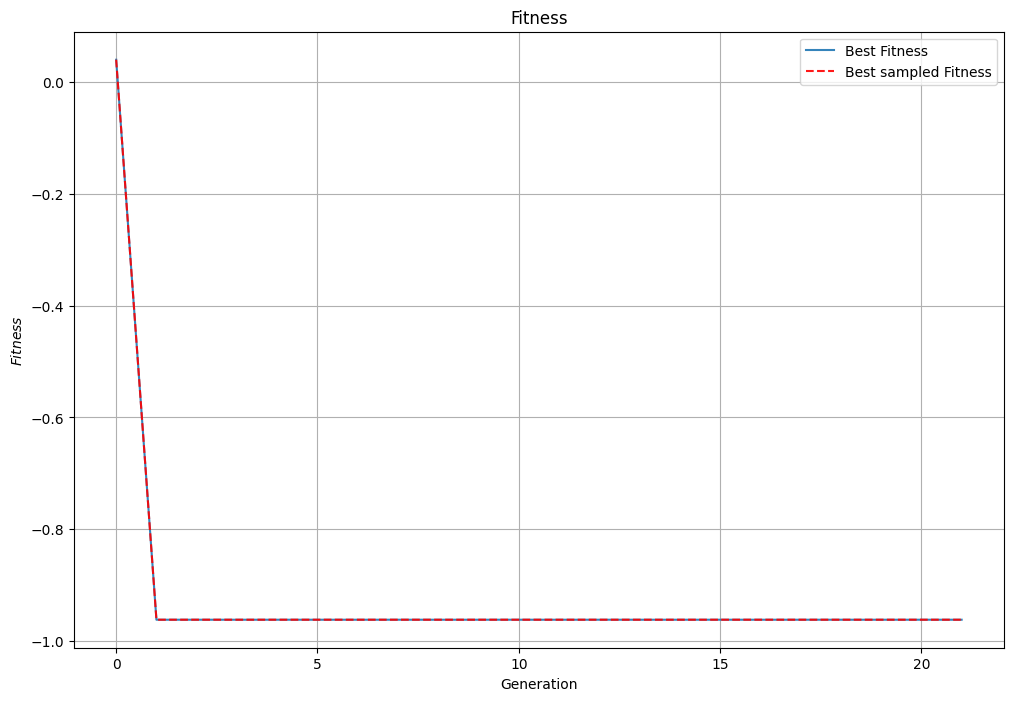

In [6]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 8))

plt.plot(np.arange(0, len(egparesultground.data), 1),egparesultground.data[:,0,-1], '-', label='Best Fitness', alpha=0.9)
plt.plot(np.arange(0, len(egparesultground.data), 1),egparesultground.best_sampled[:, 0, -1], 'r--', label='Best sampled Fitness', alpha=0.9)
# plt.ylim((-1, 0.2))
# plt.xlim((38, 75))
plt.grid()
plt.gca().set_title(r'Fitness')
plt.xlabel('Generation')
plt.gca().set_ylabel(r'$Fitness$')
plt.legend(loc = 'upper right');

In [7]:
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot_cell_06(i):
    plt.clf()  # Clear previous plot
    plt.figure(figsize=(20, 12))
    plt.suptitle(f'Generation number {i}')
    
    for inds in range(int(len(egparesultground.data))):
        plt.plot(np.linspace(0, 5, n_variables), egparesultground.data[i,inds,:-1])#, label='Best solutions')

    plt.plot(np.linspace(0, 5, n_variables), Psi_n(1), 'k-', label='Analytical solution')
    plt.gca().set_title('Wave function $\Psi(x)$')
    plt.xlabel('x')
    plt.gca().set_ylabel(r'$\Psi(x)$')
    # Define the vertices of the rectangle
    x = [-0.2, -0.2, 0.02, 0.02]
    x2 = [5.02, 5.02, 5.2, 5.2]
    y = [0, 0.7, 0.7, 0]
    # Fill the area defined by the vertices
    plt.fill(x, y, color='black')
    plt.fill(x2, y, 'black')
    plt.hlines(y=0, xmin=0, xmax=5.2, colors='k')
    plt.legend();

#Create a slider widget
generation_slider_cell_06 = widgets.IntSlider(value=0, min=0, max=len(egparesultground.data)-1, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot_cell_06 function
interact(update_plot_cell_06, i=generation_slider_cell_06);


interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=21), Outpu…

In [8]:
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import interact

# Interactive posterior mean and 95% confidence interval for eigenstate n=1.
def update_infinite_well_ci_state_1(generation):
    plt.clf()
    fig, ax = plt.subplots(figsize=(12, 8))
    mean_prediction, std_prediction = egparesultground.GP_hist[generation].predict(X_grid_well, return_std=True)
    x_values = X_grid_well.ravel()

    ax.plot(x_values, mean_prediction, label="GP mean prediction")
    ax.fill_between(
        x_values,
        mean_prediction - 1.96 * std_prediction,
        mean_prediction + 1.96 * std_prediction,
        alpha=0.35,
        label="95% confidence interval",
    )
    ax.plot(x_values, Psi_n(1), "r--", label="Analytical solution")
    ax.set_title(f"Infinite well: eigenstate n=1, generation {generation}")
    ax.set_xlabel("x")
    ax.set_ylabel(r"$\Psi(x)$")
    ax.grid(True, alpha=0.25)
    ax.legend()
    fig.tight_layout()

infinite_well_generation_slider_1 = widgets.IntSlider(
    value=0,
    min=0,
    max=len(egparesultground.GP_hist) - 1,
    step=1,
    description="Generation",
    layout=widgets.Layout(width="100%"),
)
interact(update_infinite_well_ci_state_1, generation=infinite_well_generation_slider_1);


interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=20), Outpu…

In [9]:
Psi_fund=egparesultground.data[-1, 0, :-1]
E_fund = np.sqrt(-np.log(-egparesultground.data[-1,0,-1])) # con definición exponencial de función de coste la energía se determina a partir del fitness así
params = {'L':L, 'E': E_fund, 'Psi': Psi_fund}

In [10]:
np.mean(abs(Psi_n(0)-Psi_fund))

np.float64(0.39457914529443333)

In [11]:
Gaussian = EGPA(size_gen=500, grid_X=X_grid_well, max_iter=200, dead_iter=50, alpha=0.1, elite_factor=0.05, init_kernels=5,parallelize=True, init_data=(X_train, Y_train), analysis_mode=True)
egparesultexc1 = Gaussian.minimize(oneD_wellExpEexcitated, params, exp_from = 4, output_runtime=True)

IT:  0 	Best cost:  0.3685169363614345
IT:  1 	Best cost:  0.35445593740007597
IT:  2 	Best cost:  0.35183026395081496
IT:  3 	Best cost:  -0.7033167108843426
IT:  4 	Best cost:  -0.7033397373639754
IT:  5 	Best cost:  -0.7036928226893266
IT:  6 	Best cost:  -0.7039404582408111
IT:  7 	Best cost:  -0.7039404582408111
IT:  8 	Best cost:  -0.7039404582408111
IT:  9 	Best cost:  -0.7039404582408111
IT:  10 	Best cost:  -0.7039404582408111
IT:  11 	Best cost:  -0.7042299358659245
IT:  12 	Best cost:  -0.7042299358659245
IT:  13 	Best cost:  -0.7042299358659245
IT:  14 	Best cost:  -0.7042299358659245
IT:  15 	Best cost:  -0.7042299358659245
IT:  16 	Best cost:  -0.7042299358659245
IT:  17 	Best cost:  -0.7042299358659245
IT:  18 	Best cost:  -0.7045101613264274
IT:  19 	Best cost:  -0.7045101613264274
IT:  20 	Best cost:  -0.7045101613264274
IT:  21 	Best cost:  -0.7045101613264274
IT:  22 	Best cost:  -0.7045101613264274
IT:  23 	Best cost:  -0.7045101613264274
IT:  24 	Best cost:  -0.704

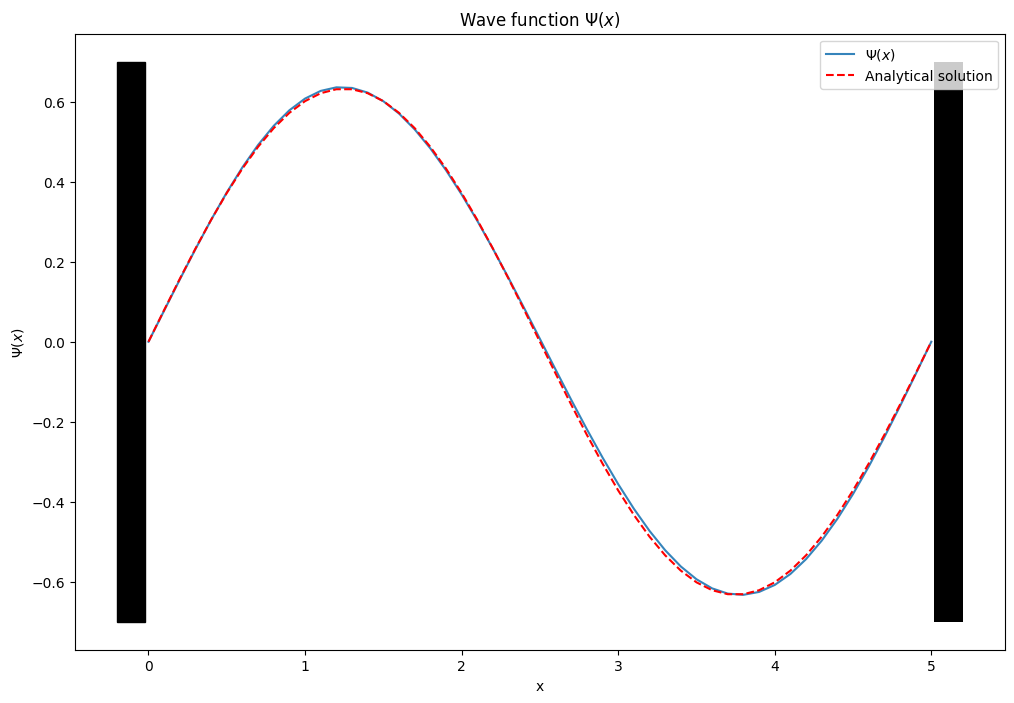

In [12]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 8))

plt.plot(np.linspace(0, 5, n_variables),egparesultexc1.data[-1,0,:-1], '-', label='$\Psi(x)$', alpha=0.9)
plt.plot(np.linspace(0, 5, n_variables), Psi_n(2), 'r--', label='Analytical solution')
plt.gca().set_title('Wave function $\Psi(x)$')
plt.xlabel('x')
plt.gca().set_ylabel(r'$\Psi(x)$')
plt.legend(loc = 'upper right')
# Define the vertices of the rectangle
x = [-0.2, -0.2, -0.02, -0.02]
x2 = [5.02, 5.02, 5.2, 5.2]
y = [-0.70, 0.7, 0.7, -0.7]
# Fill the area defined by the vertices
plt.fill(x, y, color='black')
plt.fill(x2, y, 'black')
#plt.hlines(y=0, xmin=0, xmax=5.2, colors='k');

In [13]:
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot_cell_12(i):
    plt.clf()  # Clear previous plot
    plt.figure(figsize=(20, 12))
    plt.suptitle(f'Generation number {i}')
    
    for inds in range(len(egparesultexc1.data)):
        plt.plot(np.linspace(0, 5, n_variables), egparesultexc1.data[i,inds,:-1])#, label='Best solutions')

    plt.plot(np.linspace(0, 5, n_variables), Psi_n(2), 'k-', label='Analytical solution')
    plt.gca().set_title('Wave function $\Psi(x)$')
    plt.xlabel('x')
    plt.gca().set_ylabel(r'$\Psi(x)$')
    # Define the vertices of the rectangle
    x = [-0.2, -0.2, -0.02, -0.02]
    x2 = [5.02, 5.02, 5.2, 5.2]
    y = [-0.70, 0.7, 0.7, -0.7]
    # Fill the area defined by the vertices
    plt.fill(x, y, color='black')
    plt.fill(x2, y, 'black')
    plt.hlines(y=0, xmin=0, xmax=5.2, colors='k')
    plt.legend();

#Create a slider widget
generation_slider_cell_12 = widgets.IntSlider(value=0, min=0, max=len(egparesultexc1.data)-1, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot_cell_12 function
interact(update_plot_cell_12, i=generation_slider_cell_12);


interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=68), Outpu…

In [14]:
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import interact

# Interactive posterior mean and 95% confidence interval for eigenstate n=2.
def update_infinite_well_ci_state_2(generation):
    plt.clf()
    fig, ax = plt.subplots(figsize=(12, 8))
    mean_prediction, std_prediction = egparesultexc1.GP_hist[generation].predict(X_grid_well, return_std=True)
    x_values = X_grid_well.ravel()

    ax.plot(x_values, mean_prediction, label="GP mean prediction")
    ax.fill_between(
        x_values,
        mean_prediction - 1.96 * std_prediction,
        mean_prediction + 1.96 * std_prediction,
        alpha=0.35,
        label="95% confidence interval",
    )
    ax.plot(x_values, Psi_n(2), "r--", label="Analytical solution")
    ax.set_title(f"Infinite well: eigenstate n=2, generation {generation}")
    ax.set_xlabel("x")
    ax.set_ylabel(r"$\Psi(x)$")
    ax.grid(True, alpha=0.25)
    ax.legend()
    fig.tight_layout()

infinite_well_generation_slider_2 = widgets.IntSlider(
    value=0,
    min=0,
    max=len(egparesultexc1.GP_hist) - 1,
    step=1,
    description="Generation",
    layout=widgets.Layout(width="100%"),
)
interact(update_infinite_well_ci_state_2, generation=infinite_well_generation_slider_2);


interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=67), Outpu…

In [15]:
Psi_1=egparesultexc1.data[-1, 0, :-1]
E1 = np.sqrt(-np.log(-egparesultexc1.data[-1,0,-1])) # con definición exponencial de función de coste la energía se determina a partir del fitness así
params = {'L':L, 'E0': E_fund, 'Psi0': Psi_fund, 'E1':E1, 'Psi1': Psi_1}

In [16]:
Gaussian = EGPA(size_gen=600, grid_X=X_grid_well, max_iter=600, dead_iter=60, alpha=0.1, elite_factor=0.05, init_kernels=6,parallelize=True, init_data=(X_train, Y_train), analysis_mode=True)
egparesultexc2 = Gaussian.minimize(oneD_wellExpEexcitated3, params, exp_from = 5, output_runtime=True)

IT:  0 	Best cost:  1.3744907716072305
IT:  1 	Best cost:  1.18237981759537
IT:  2 	Best cost:  0.9817640909954211
IT:  3 	Best cost:  0.9779235788477522
IT:  4 	Best cost:  -0.37637491734070894
IT:  5 	Best cost:  -0.3771242725992292
IT:  6 	Best cost:  -0.3771242725992292
IT:  7 	Best cost:  -0.37823380634368586
IT:  8 	Best cost:  -0.37823380634368586
IT:  9 	Best cost:  -0.37823380634368586
IT:  10 	Best cost:  -0.37823380634368586
IT:  11 	Best cost:  -0.37823380634368586
IT:  12 	Best cost:  -0.37823380634368586
IT:  13 	Best cost:  -0.37823380634368586
IT:  14 	Best cost:  -0.37823380634368586
IT:  15 	Best cost:  -0.37826442120496623
IT:  16 	Best cost:  -0.37826442120496623
IT:  17 	Best cost:  -0.3787284116705387
IT:  18 	Best cost:  -0.3787284116705387
IT:  19 	Best cost:  -0.3787284116705387
IT:  20 	Best cost:  -0.3787284116705387
IT:  21 	Best cost:  -0.3787284116705387
IT:  22 	Best cost:  -0.3787284116705387
IT:  23 	Best cost:  -0.3787284116705387
IT:  24 	Best cost:  

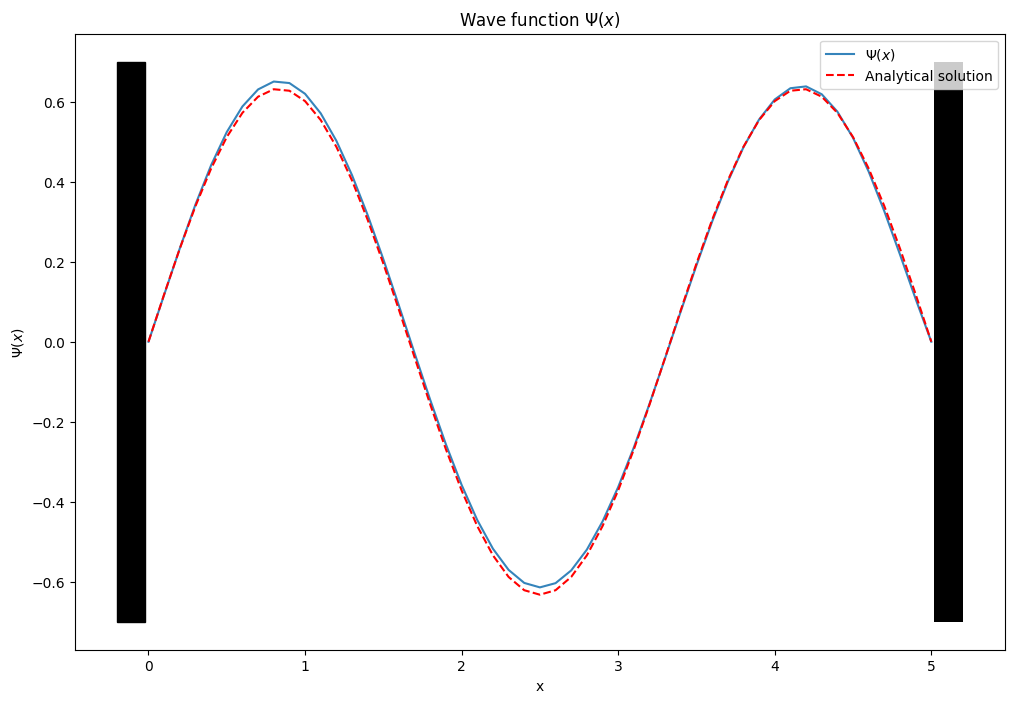

In [17]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 8))

plt.plot(np.linspace(0, 5, n_variables),egparesultexc2.data[-1,0,:-1], '-', label='$\Psi(x)$', alpha=0.9)
plt.plot(np.linspace(0, 5, n_variables), Psi_n(3), 'r--', label='Analytical solution')
plt.gca().set_title('Wave function $\Psi(x)$')
plt.xlabel('x')
plt.gca().set_ylabel(r'$\Psi(x)$')
plt.legend(loc = 'upper right')
# Define the vertices of the rectangle
x = [-0.2, -0.2, -0.02, -0.02]
x2 = [5.02, 5.02, 5.2, 5.2]
y = [-0.70, 0.7, 0.7, -0.7]
# Fill the area defined by the vertices
plt.fill(x, y, color='black')
plt.fill(x2, y, 'black')
#plt.hlines(y=0, xmin=0, xmax=5.2, colors='k');

In [18]:
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot_cell_17(i):
    plt.clf()  # Clear previous plot
    plt.figure(figsize=(20, 12))
    plt.suptitle(f'Generation number {i}')
    
    for inds in range(int(len(egparesultexc2.data))):
        plt.plot(np.linspace(0, 5, n_variables), egparesultexc2.data[i,inds,:-1])#, label='Best solutions')

    plt.plot(np.linspace(0, 5, n_variables), Psi_n(3), 'k-', label='Analytical solution')
    plt.gca().set_title('Wave function $\Psi(x)$')
    plt.xlabel('x')
    plt.gca().set_ylabel(r'$\Psi(x)$')
    # Define the vertices of the rectangle
    x = [-0.2, -0.2, -0.02, -0.02]
    x2 = [5.02, 5.02, 5.2, 5.2]
    y = [-0.70, 0.7, 0.7, -0.7]
    # Fill the area defined by the vertices
    plt.fill(x, y, color='black')
    plt.fill(x2, y, 'black')
    plt.hlines(y=0, xmin=0, xmax=5.2, colors='k')
    plt.legend();

#Create a slider widget
generation_slider_cell_17 = widgets.IntSlider(value=0, min=0, max=len(egparesultexc2.data)-1, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot_cell_17 function
interact(update_plot_cell_17, i=generation_slider_cell_17);


interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=115), Outp…

In [19]:
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import interact

# Interactive posterior mean and 95% confidence interval for eigenstate n=3.
def update_infinite_well_ci_state_3(generation):
    plt.clf()
    fig, ax = plt.subplots(figsize=(12, 8))
    mean_prediction, std_prediction = egparesultexc2.GP_hist[generation].predict(X_grid_well, return_std=True)
    x_values = X_grid_well.ravel()

    ax.plot(x_values, mean_prediction, label="GP mean prediction")
    ax.fill_between(
        x_values,
        mean_prediction - 1.96 * std_prediction,
        mean_prediction + 1.96 * std_prediction,
        alpha=0.35,
        label="95% confidence interval",
    )
    ax.plot(x_values, Psi_n(3), "r--", label="Analytical solution")
    ax.set_title(f"Infinite well: eigenstate n=3, generation {generation}")
    ax.set_xlabel("x")
    ax.set_ylabel(r"$\Psi(x)$")
    ax.grid(True, alpha=0.25)
    ax.legend()
    fig.tight_layout()

infinite_well_generation_slider_3 = widgets.IntSlider(
    value=0,
    min=0,
    max=len(egparesultexc2.GP_hist) - 1,
    step=1,
    description="Generation",
    layout=widgets.Layout(width="100%"),
)
interact(update_infinite_well_ci_state_3, generation=infinite_well_generation_slider_3);


interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=114), Outp…

In [20]:
Psi_2=egparesultexc2.data[-1, 0, :-1]
E2 = np.sqrt(-np.log(-egparesultexc2.data[-1,0,-1])) # con definición exponencial de función de coste la energía se determina a partir del fitness así
params = {'L':L, 'E0': E_fund, 'Psi0': Psi_fund, 'E1':E1, 'Psi1': Psi_1, 'E2': E2, 'Psi2': Psi_2}

In [21]:
Gaussian = EGPA(size_gen=600, grid_X=X_grid_well, max_iter=600, dead_iter=60, alpha=0.1, elite_factor=0.05, init_kernels=6,parallelize=True, init_data=(X_train, Y_train), analysis_mode=True)
egparesultexc3 = Gaussian.minimize(oneD_wellExpEexcitated4, params, exp_from = 10, output_runtime=True)

IT:  0 	Best cost:  4.2511818730460345
IT:  1 	Best cost:  4.2511818730460345
IT:  2 	Best cost:  3.333967435518367
IT:  3 	Best cost:  3.333967435518367
IT:  4 	Best cost:  3.333967435518367
IT:  5 	Best cost:  3.333967435518367
IT:  6 	Best cost:  3.333967435518367
IT:  7 	Best cost:  3.333967435518367
IT:  8 	Best cost:  3.333967435518367
IT:  9 	Best cost:  -7.385036139692913e-05
IT:  10 	Best cost:  -7.385036139692913e-05
IT:  11 	Best cost:  -7.385036139692913e-05
IT:  12 	Best cost:  -7.385036139692913e-05
IT:  13 	Best cost:  -9.537271499558697e-05
IT:  14 	Best cost:  -0.00015993321267036484
IT:  15 	Best cost:  -0.0005205219465902338
IT:  16 	Best cost:  -0.0008637784796445726
IT:  17 	Best cost:  -0.0018550065196088598
IT:  18 	Best cost:  -0.00376699125062524
IT:  19 	Best cost:  -0.010031255002325929
IT:  20 	Best cost:  -0.01308260767678515
IT:  21 	Best cost:  -0.03161502312046766
IT:  22 	Best cost:  -0.0540986763390172
IT:  23 	Best cost:  -0.06901753381414545
IT:  24 

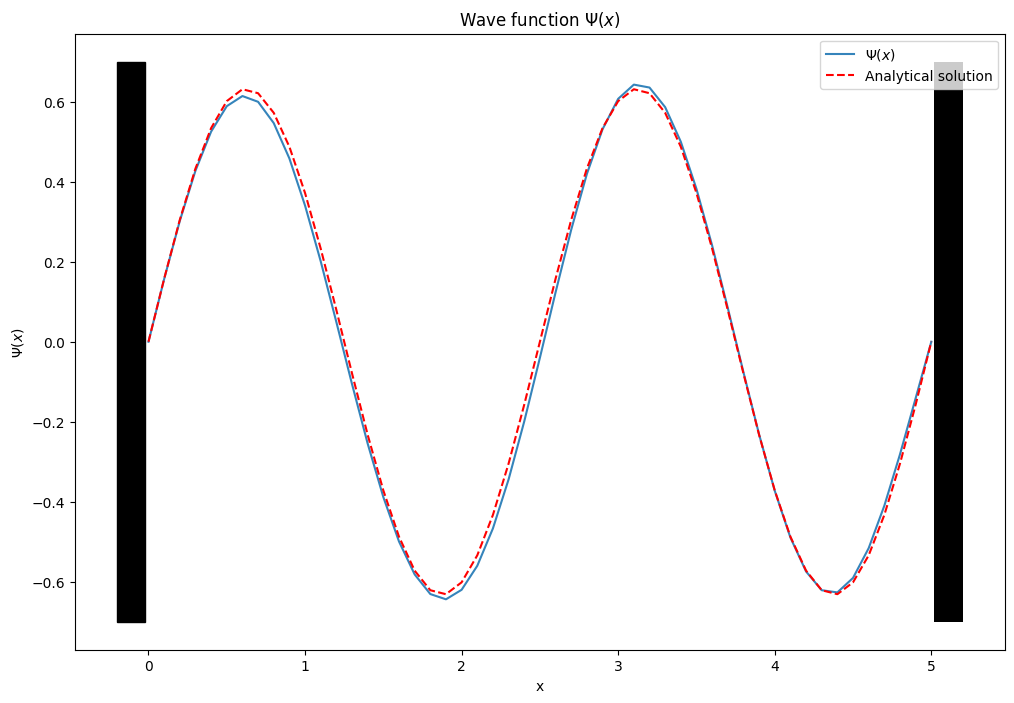

In [22]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 8))

plt.plot(np.linspace(0, 5, n_variables),egparesultexc3.data[-1,0,:-1], '-', label='$\Psi(x)$', alpha=0.9)
plt.plot(np.linspace(0, 5, n_variables), Psi_n(4), 'r--', label='Analytical solution')
plt.gca().set_title('Wave function $\Psi(x)$')
plt.xlabel('x')
plt.gca().set_ylabel(r'$\Psi(x)$')
plt.legend(loc = 'upper right')
# Define the vertices of the rectangle
x = [-0.2, -0.2, -0.02, -0.02]
x2 = [5.02, 5.02, 5.2, 5.2]
y = [-0.70, 0.7, 0.7, -0.7]
# Fill the area defined by the vertices
plt.fill(x, y, color='black')
plt.fill(x2, y, 'black')
#plt.hlines(y=0, xmin=0, xmax=5.2, colors='k');

In [23]:
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot_cell_22(i):
    plt.clf()  # Clear previous plot
    plt.figure(figsize=(20, 12))
    plt.suptitle(f'Generation number {i}')
    
    for inds in range(int(len(egparesultexc3.data))):
        plt.plot(np.linspace(0, 5, n_variables), egparesultexc3.data[i,inds,:-1])#, label='Best solutions')

    plt.plot(np.linspace(0, 5, n_variables), Psi_n(4), 'k-', label='Analytical solution')
    plt.gca().set_title('Wave function $\Psi(x)$')
    plt.xlabel('x')
    plt.gca().set_ylabel(r'$\Psi(x)$')
    # Define the vertices of the rectangle
    x = [-0.2, -0.2, -0.02, -0.02]
    x2 = [5.02, 5.02, 5.2, 5.2]
    y = [-0.70, 0.7, 0.7, -0.7]
    # Fill the area defined by the vertices
    plt.fill(x, y, color='black')
    plt.fill(x2, y, 'black')
    plt.hlines(y=0, xmin=0, xmax=5.2, colors='k')
    plt.legend();

#Create a slider widget
generation_slider_cell_22 = widgets.IntSlider(value=0, min=0, max=len(egparesultexc3.data)-1, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot_cell_22 function
interact(update_plot_cell_22, i=generation_slider_cell_22);


interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=116), Outp…

In [24]:
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import interact

# Interactive posterior mean and 95% confidence interval for eigenstate n=4.
def update_infinite_well_ci_state_4(generation):
    plt.clf()
    fig, ax = plt.subplots(figsize=(12, 8))
    mean_prediction, std_prediction = egparesultexc3.GP_hist[generation].predict(X_grid_well, return_std=True)
    x_values = X_grid_well.ravel()

    ax.plot(x_values, mean_prediction, label="GP mean prediction")
    ax.fill_between(
        x_values,
        mean_prediction - 1.96 * std_prediction,
        mean_prediction + 1.96 * std_prediction,
        alpha=0.35,
        label="95% confidence interval",
    )
    ax.plot(x_values, Psi_n(4), "r--", label="Analytical solution")
    ax.set_title(f"Infinite well: eigenstate n=4, generation {generation}")
    ax.set_xlabel("x")
    ax.set_ylabel(r"$\Psi(x)$")
    ax.grid(True, alpha=0.25)
    ax.legend()
    fig.tight_layout()

infinite_well_generation_slider_4 = widgets.IntSlider(
    value=0,
    min=0,
    max=len(egparesultexc3.GP_hist) - 1,
    step=1,
    description="Generation",
    layout=widgets.Layout(width="100%"),
)
interact(update_infinite_well_ci_state_4, generation=infinite_well_generation_slider_4);


interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=115), Outp…

# **Quantum harmonic oscillator**

Another typical problem is the harmonic oscillator (classically arising from a force of the form $F = -kx$). In this case, the potential is $V(x) = \frac{1}{2}m\omega^2 x^2$, where $x$ is the displacement from the equilibrium position (the potential well), so the Hamiltonian is written as:

$$\hat{H} | \Psi\rangle = E | \Psi\rangle \quad \longrightarrow \quad
\left(-\frac{\hbar^2}{2m}\frac{d^2}{dx^2} + V(x)\right)\Psi(x) \longrightarrow \quad \left(-\frac{\hbar^2}{2m}\frac{d^2}{dx^2} + \frac{1}{2}m\omega^2 x^2 \right)\Psi(x)= E \Psi(x)$$

The analytical solutions depend on Hermite polynomials, with their corresponding energies:

$$ \Psi_n = N_n e^{-\beta^2 x^2 / 2} H_n (\beta x ) \quad ; \quad E_n = (n + \frac{1}{2}) \hbar \omega \quad \text{with} \,\,\, n = 0, 1, 2, ...$$

where $N_n$ is the normalization constant for each solution, $\beta = \sqrt{m \omega / \hbar}$, and $H_n(y)$ is the Hermite polynomial of degree $n$, which has the following forms:

$$H_0(y) = 1 \quad H_1(y) = 2y \quad H_2(y) = 4y^2 - 2 \quad H_3(y) = 8y^3 - 12y$$

We will use the following optimization function:

$$ Z = \left[\frac{\langle\Psi|\hat{H}|\Psi\rangle}{\langle\Psi|\Psi\rangle} - E_l\right]^2 $$

In [25]:
from EGPA import *
from OptFunctions.oneDQHarmOscillatorfunctions import *
from utils import _parallel_apply_along_axis
import warnings
warnings.filterwarnings("ignore")

In [26]:
n_variables = 51
X_grid_qho = np.linspace(start=-4, stop=4, num=n_variables).reshape(-1,1) #para que sean n_variables filas y 1 columna
#Ahora definimos las observaciones que hemos hecho de la función. En este caso son las condiciones de contorno del problema
#Los datos que conocemos son las amplitudes en x=-4 (-inf) x=4 (inf) que son 0
X_train = X_grid_qho[[0,-1]]
Y_train = np.linspace(start=0, stop=0, num=2).reshape(-1,1) #Para que sea 2D array
params = {'x':X_grid_qho}

In [27]:
#Analytical solutions definitions

#Ground state
APsi0 = np.exp(-X_grid_qho**2/2)
integral =0
for i in range(len(APsi0)):
    integral = integral + (APsi0[i]**2)*((X_grid_qho[-1]-X_grid_qho[0])/(len(APsi0)-1))

B = (1/integral)**0.5
APsi0 = B * APsi0

#1st excitated state
APsi1 = np.exp(-X_grid_qho**2/2)*2*X_grid_qho
integral =0
for i in range(len(APsi1)):
    integral = integral + (APsi1[i]**2)*((X_grid_qho[-1]-X_grid_qho[0])/(len(APsi1)-1))

B = (1/integral)**0.5
APsi1 = B * APsi1

#if results_dict['eda_resultExpE1'].sel_inds_hist[-1, 0, :-1][10]>0:
   # APsi1 = -APsi1


#2nd excitated state
APsi2 = np.exp(-X_grid_qho**2/2)*(4*X_grid_qho**2-2)
integral =0
for i in range(len(APsi2)):
    integral = integral + (APsi2[i]**2)*((X_grid_qho[-1]-X_grid_qho[0])/(len(APsi2)-1))

B = (1/integral)**0.5
APsi2 = B * APsi2

#if results_dict['eda_resultExpE2'].sel_inds_hist[-1, 0, :-1][3]<0:
   # APsi2=-APsi2

#3rd excitated state
APsi3 = np.exp(-X_grid_qho**2/2)*(8*X_grid_qho**3-12*X_grid_qho)
integral =0
for i in range(len(APsi3)):
    integral = integral + (APsi3[i]**2)*((X_grid_qho[-1]-X_grid_qho[0])/(len(APsi3)-1))

B = (1/integral)**0.5
APsi3 = B * APsi3

#if results_dict['eda_resultExpE3'].sel_inds_hist[-1,0,:-1][10]>0:
   # APsi3 = -APsi3 

In [28]:
Gaussian = EGPA(size_gen=400, grid_X=X_grid_qho, max_iter=300, dead_iter=30, alpha=0.1, elite_factor=0.05, init_kernels=4,parallelize=True, init_data=(X_train, Y_train), analysis_mode=True)
egparesultQHOground = Gaussian.minimize(oneDHOExpE, params, exp_from = 3, output_runtime=True)

IT:  0 	Best cost:  [0.28874864]
IT:  1 	Best cost:  [0.28874864]
IT:  2 	Best cost:  [-0.03872002]
IT:  3 	Best cost:  [-0.0582695]
IT:  4 	Best cost:  [-0.0638715]
IT:  5 	Best cost:  [-0.06822184]
IT:  6 	Best cost:  [-0.07053366]
IT:  7 	Best cost:  [-0.07170836]
IT:  8 	Best cost:  [-0.07170836]
IT:  9 	Best cost:  [-0.07170836]
IT:  10 	Best cost:  [-0.07210463]
IT:  11 	Best cost:  [-0.07286133]
IT:  12 	Best cost:  [-0.07286133]
IT:  13 	Best cost:  [-0.07286133]
IT:  14 	Best cost:  [-0.07521566]
IT:  15 	Best cost:  [-0.07521566]
IT:  16 	Best cost:  [-0.07521566]
IT:  17 	Best cost:  [-0.07521566]
IT:  18 	Best cost:  [-0.07521566]
IT:  19 	Best cost:  [-0.07521566]
IT:  20 	Best cost:  [-0.07521566]
IT:  21 	Best cost:  [-0.07521566]
IT:  22 	Best cost:  [-0.07521566]
IT:  23 	Best cost:  [-0.07521566]
IT:  24 	Best cost:  [-0.07521566]
IT:  25 	Best cost:  [-0.07521566]
IT:  26 	Best cost:  [-0.07521566]
IT:  27 	Best cost:  [-0.07521566]
IT:  28 	Best cost:  [-0.07521566]

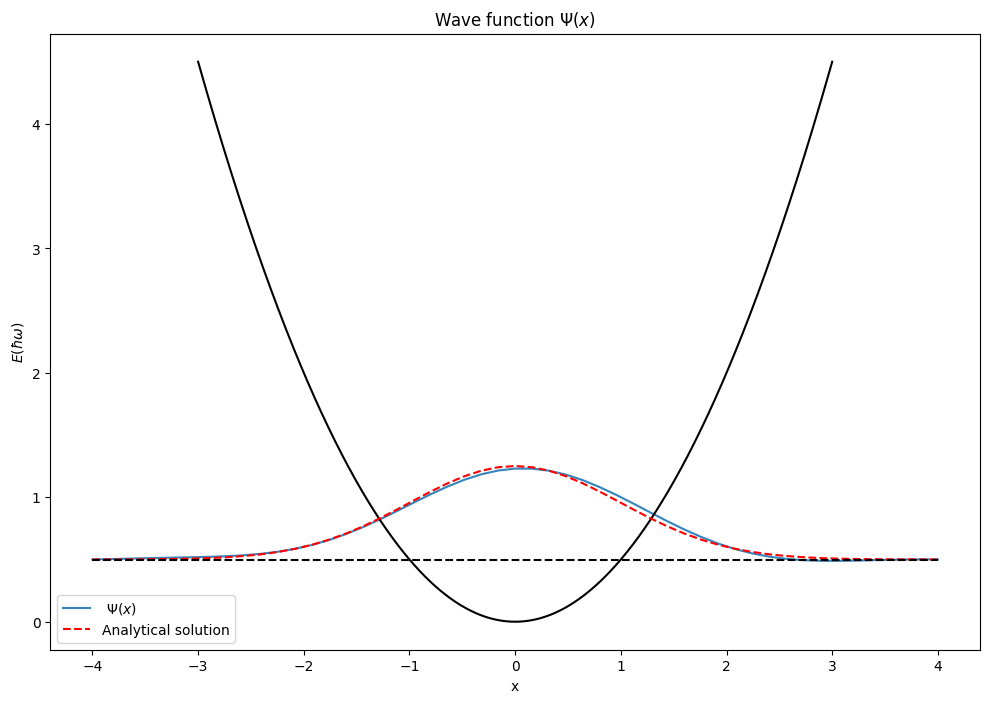

In [29]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 8))
plt.plot(X_grid_qho, 0.5+egparesultQHOground.data[-1, 0, :-1], '-', label=f' $\Psi(x)$', alpha=0.9)

plt.plot(np.linspace(-3,3, 1000), 0.5*np.linspace(-3,3,1000)**2, 'k-')
plt.plot(np.linspace(-4,4,n_variables), 0.5+APsi0, 'r--', label='Analytical solution')
plt.plot(np.linspace(-4,4,2), np.linspace(0.5,0.5,2), 'k--')
plt.gca().set_title('Wave function $\Psi(x)$')
plt.xlabel('x')
plt.gca().set_ylabel(r'$E (\hbar \omega)$')
plt.legend();

In [30]:
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot_cell_30(i):
    plt.clf()  # Clear previous plot
    plt.figure(figsize=(20, 10))
    plt.suptitle(f'Generation number {i}')
    
    for inds in range(int(egparesultQHOground.data.shape[1]*0.1)):
        plt.plot(X_grid_qho, 0.5+egparesultQHOground.data[i,inds,:-1])#, label='Best solutions')

    #plt.plot(X_grid_qho, APsi0, 'k-', label='Analytical solution')
    plt.gca().set_title('Wave function $\Psi(x)$')
    plt.xlabel('x')
    plt.gca().set_ylabel(r'$\Psi(x)$')
    plt.plot(np.linspace(-3,3, 1000), 0.5*np.linspace(-3,3,1000)**2, 'k-')
    plt.plot(X_grid_qho, 0.5+APsi0, 'r--', label='Analytical solution')
    plt.plot(np.linspace(-4,4,2), np.linspace(0.5,0.5,2), 'k--')
    plt.legend();

#Create a slider widget
generation_slider_cell_30 = widgets.IntSlider(value=0, min=0, max=len(egparesultQHOground.data)-1, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot_cell_30 function
interact(update_plot_cell_30, i=generation_slider_cell_30);


interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=85), Outpu…

In [31]:
import matplotlib.pyplot as plt
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot_cell_31(i):
    plt.clf()  # Clear previous plot
    plt.figure(figsize=(20, 12))
    plt.suptitle(f'Generation number {i}')
    
    


    mean_prediction, std_prediction = egparesultQHOground.GP_hist[i].predict(X_grid_qho, return_std=True)
    plt.plot(X_grid_qho, 0.5+mean_prediction, label="Mean prediction")
    plt.fill_between(
        X_grid_qho.ravel(),
        0.5+ mean_prediction - 1.96 * std_prediction,
        0.5+mean_prediction + 1.96 * std_prediction,
        alpha=0.5,
        label=r"95% confidence interval",
    )

    plt.gca().set_title('Wave function $\Psi(x)$')
    plt.xlabel('x')
    plt.gca().set_ylabel(r'$\Psi(x)$')
    plt.plot(np.linspace(-3,3, 1000), 0.5*np.linspace(-3,3,1000)**2, 'k-')
    plt.plot(np.linspace(-4,4,n_variables), 0.5+1*APsi0, 'r--', label='Analytical solution')
    plt.plot(np.linspace(-4,4,2), np.linspace(0.5,0.5,2), 'k--')
    plt.legend();

#Create a slider widget
generation_slider_cell_31 = widgets.IntSlider(value=0, min=0, max=len(egparesultQHOground.data)-1, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot_cell_31 function
interact(update_plot_cell_31, i=generation_slider_cell_31);

interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=85), Outpu…

In [32]:
Psi_ground=egparesultQHOground.data[-1, 0, :-1]
cons = 10 ### FACTOR CONSTANTE que MULTIPLICA EL EXPONENTE EN FUNCIÓN DE COSTE 
E0 = np.sqrt(-np.log(-egparesultQHOground.data[-1,0,-1])/cons) # con definición exponencial de función de coste la energía se determina a partir del fitness así 
params = {'x':X_grid_qho, 'E0': E0, 'Psi0': Psi_ground}

In [33]:
Gaussian = EGPA(size_gen=400, grid_X=X_grid_qho, max_iter=300, dead_iter=30, alpha=0.05, elite_factor=0.025, init_kernels=4,parallelize=True, init_data=(X_train, Y_train), analysis_mode=True)
egparesultQHO1 = Gaussian.minimize(oneDHOExpE1, params, exp_from = 5, output_runtime=True)

IT:  0 	Best cost:  [1.36140831]
IT:  1 	Best cost:  [1.36140831]
IT:  2 	Best cost:  [1.23113661]
IT:  3 	Best cost:  [1.11440334]
IT:  4 	Best cost:  [-2.47040062e-05]
IT:  5 	Best cost:  [-3.72451082e-05]
IT:  6 	Best cost:  [-3.98968159e-05]
IT:  7 	Best cost:  [-4.07640734e-05]
IT:  8 	Best cost:  [-5.14628855e-05]
IT:  9 	Best cost:  [-5.14628855e-05]
IT:  10 	Best cost:  [-5.14628855e-05]
IT:  11 	Best cost:  [-5.14628855e-05]
IT:  12 	Best cost:  [-5.14628855e-05]
IT:  13 	Best cost:  [-5.14628855e-05]
IT:  14 	Best cost:  [-5.14628855e-05]
IT:  15 	Best cost:  [-5.14628855e-05]
IT:  16 	Best cost:  [-5.14628855e-05]
IT:  17 	Best cost:  [-5.14628855e-05]
IT:  18 	Best cost:  [-5.14628855e-05]
IT:  19 	Best cost:  [-5.14628855e-05]
IT:  20 	Best cost:  [-5.14628855e-05]
IT:  21 	Best cost:  [-5.14628855e-05]
IT:  22 	Best cost:  [-5.14628855e-05]
IT:  23 	Best cost:  [-5.14628855e-05]
IT:  24 	Best cost:  [-5.14628855e-05]
IT:  25 	Best cost:  [-5.14628855e-05]
IT:  26 	Best co

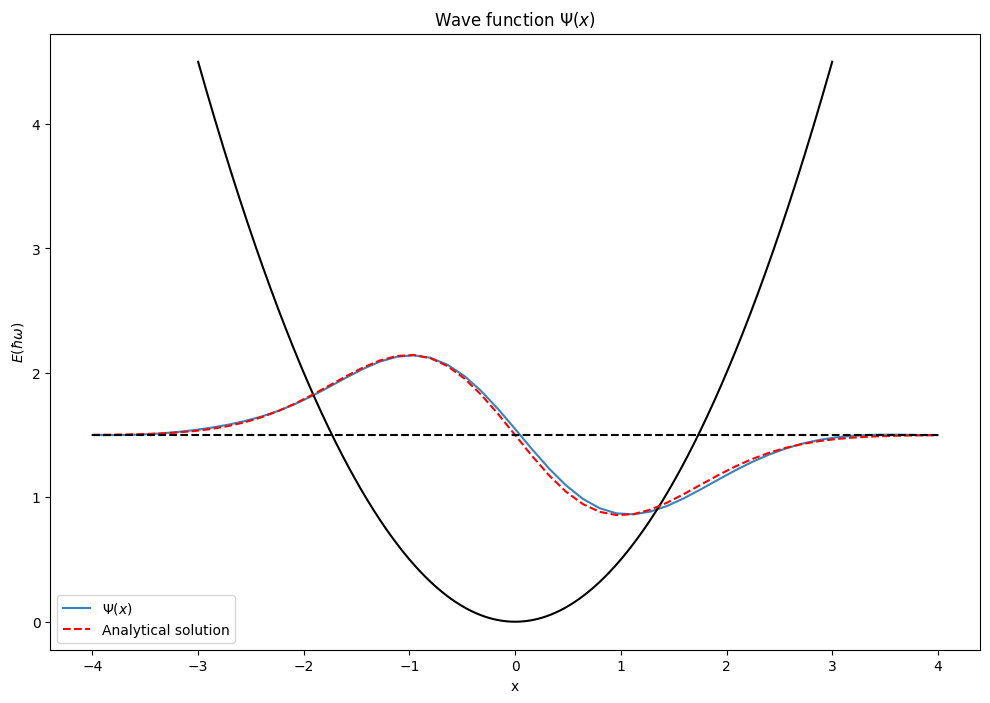

In [34]:
plt.figure(figsize=(12, 8))
plt.plot(X_grid_qho, 1.5+egparesultQHO1.data[-1,0,:-1], '-', label=f'$\Psi(x)$', alpha=0.9)
plt.plot(np.linspace(-3,3, 1000), 0.5*np.linspace(-3,3,1000)**2, 'k-')
plt.plot(X_grid_qho, 1.5+-1*APsi1, 'r--', label='Analytical solution')
plt.plot(np.linspace(-4,4,2), np.linspace(1.5,1.5,2), 'k--')
plt.gca().set_title('Wave function $\Psi(x)$')
plt.xlabel('x')
plt.gca().set_ylabel(r'$E(\hbar \omega)$')
plt.legend();

In [35]:
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot_cell_35(i):
    plt.clf()  # Clear previous plot
    plt.figure(figsize=(20, 12))
    plt.suptitle(f'Generation number {i}')
    
    for inds in range(int(egparesultQHO1.data.shape[1])):
        plt.plot(X_grid_qho, 1.5+egparesultQHO1.data[i,inds,:-1])#, label='Best solutions')

    plt.gca().set_title('Wave function $\Psi(x)$')
    plt.xlabel('x')
    plt.gca().set_ylabel(r'$\Psi(x)$')
    plt.plot(np.linspace(-3,3, 1000), 0.5*np.linspace(-3,3,1000)**2, 'k-')
    plt.plot(np.linspace(-4,4,n_variables), 1.5+-1*APsi1, 'r--', label='Analytical solution')
    plt.plot(np.linspace(-4,4,2), np.linspace(1.5,1.5,2), 'k--')
    plt.legend();

#Create a slider widget
generation_slider_cell_35 = widgets.IntSlider(value=0, min=0, max=len(egparesultQHO1.data)-1, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot_cell_35 function
interact(update_plot_cell_35, i=generation_slider_cell_35);


interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=38), Outpu…

In [36]:
import matplotlib.pyplot as plt
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot_cell_36(i):
    plt.clf()  # Clear previous plot
    plt.figure(figsize=(20, 12))
    plt.suptitle(f'Generation number {i}')
    
    


    mean_prediction, std_prediction = egparesultQHO1.GP_hist[i].predict(X_grid_qho, return_std=True)
    plt.plot(X_grid_qho, 1.5+mean_prediction, label="Mean prediction")
    plt.fill_between(
        X_grid_qho.ravel(),
        1.5+ mean_prediction - 1.96 * std_prediction,
        1.5+mean_prediction + 1.96 * std_prediction,
        alpha=0.5,
        label=r"95% confidence interval",
    )

    plt.gca().set_title('Wave function $\Psi(x)$')
    plt.xlabel('x')
    plt.gca().set_ylabel(r'$\Psi(x)$')
    plt.plot(np.linspace(-3,3, 1000), 0.5*np.linspace(-3,3,1000)**2, 'k-')
    plt.plot(np.linspace(-4,4,n_variables), 1.5+-1*APsi1, 'r--', label='Analytical solution')
    plt.plot(np.linspace(-4,4,2), np.linspace(1.5,1.5,2), 'k--')
    plt.legend();

#Create a slider widget
generation_slider_cell_36 = widgets.IntSlider(value=0, min=0, max=len(egparesultQHO1.data)-1, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot_cell_36 function
interact(update_plot_cell_36, i=generation_slider_cell_36);

interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=38), Outpu…

In [37]:
Psi1=egparesultQHO1.data[-1, 0, :-1]
cons = 10 ### FACTOR CONSTANTE que MULTIPLICA EL EXPONENTE EN FUNCIÓN DE COSTE 
E1 = np.sqrt(-np.log(-egparesultQHO1.data[-1,0,-1])/cons) # con definición exponencial de función de coste la energía se determina a partir del fitness así
params = {'x':X_grid_qho, 'E0': E0, 'Psi0': Psi_ground, 'E1':E1, 'Psi1': Psi1}

In [38]:
Gaussian = EGPA(size_gen=400, grid_X=X_grid_qho, max_iter=300, dead_iter=50, alpha=0.05, elite_factor=0.025, init_kernels=4,parallelize=True, init_data=(X_train, Y_train), analysis_mode=True)
egparesultQHO2 = Gaussian.minimize(oneDHOExpE2, params, exp_from = 5, output_runtime=True)

IT:  0 	Best cost:  [2.460158]
IT:  1 	Best cost:  [1.85670816]
IT:  2 	Best cost:  [1.73420678]
IT:  3 	Best cost:  [1.55625092]
IT:  4 	Best cost:  [-2.4430017e-06]
IT:  5 	Best cost:  [-8.9658175e-06]
IT:  6 	Best cost:  [-1.85918789e-05]
IT:  7 	Best cost:  [-3.21986754e-05]
IT:  8 	Best cost:  [-3.21986754e-05]
IT:  9 	Best cost:  [-4.09687848e-05]
IT:  10 	Best cost:  [-4.09687848e-05]
IT:  11 	Best cost:  [-4.09687848e-05]
IT:  12 	Best cost:  [-4.09687848e-05]
IT:  13 	Best cost:  [-4.09687848e-05]
IT:  14 	Best cost:  [-4.09687848e-05]
IT:  15 	Best cost:  [-4.09687848e-05]
IT:  16 	Best cost:  [-4.09687848e-05]
IT:  17 	Best cost:  [-4.09687848e-05]
IT:  18 	Best cost:  [-4.09687848e-05]
IT:  19 	Best cost:  [-4.09687848e-05]
IT:  20 	Best cost:  [-4.09687848e-05]
IT:  21 	Best cost:  [-4.09687848e-05]
IT:  22 	Best cost:  [-4.09687848e-05]
IT:  23 	Best cost:  [-4.09687848e-05]
IT:  24 	Best cost:  [-4.09687848e-05]
IT:  25 	Best cost:  [-4.09687848e-05]
IT:  26 	Best cost: 

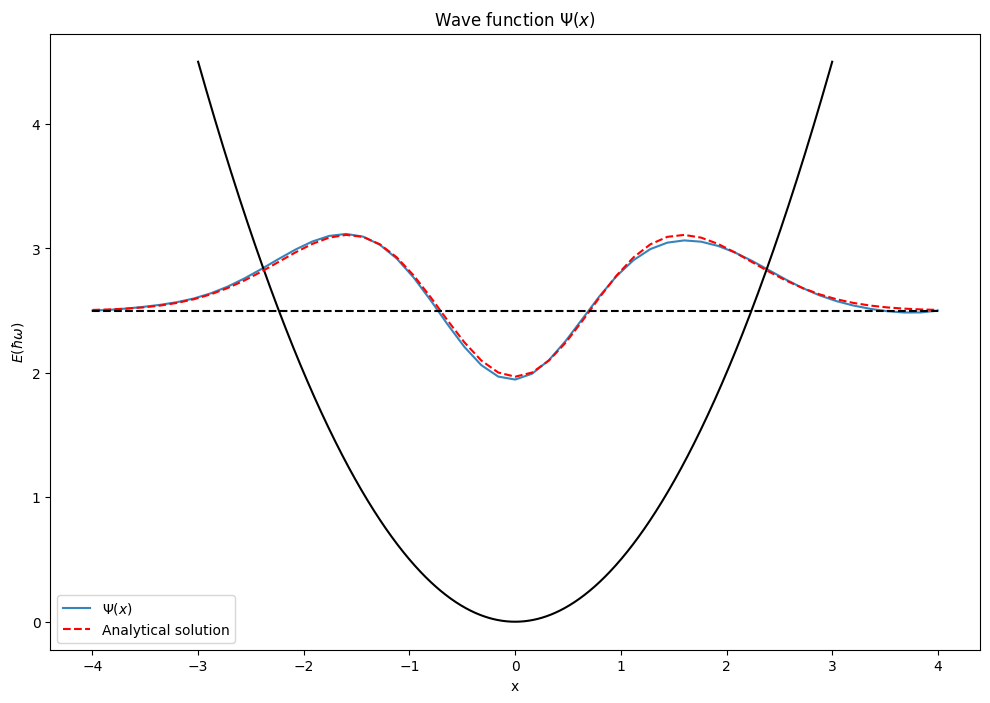

In [39]:
plt.figure(figsize=(12, 8))
plt.plot(X_grid_qho, 2.5+egparesultQHO2.data[-1,0,:-1], '-', label=f'$\Psi(x)$', alpha=0.9)
plt.plot(np.linspace(-3,3, 1000), 0.5*np.linspace(-3,3,1000)**2, 'k-')
plt.plot(X_grid_qho, 2.5+APsi2, 'r--', label='Analytical solution')
plt.plot(np.linspace(-4,4,2), np.linspace(2.5,2.5,2), 'k--')
plt.gca().set_title('Wave function $\Psi(x)$')
plt.xlabel('x')
plt.gca().set_ylabel(r'$E(\hbar \omega)$')
plt.legend();

In [40]:
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot_cell_40(i):
    plt.clf()  # Clear previous plot
    plt.figure(figsize=(20, 12))
    plt.suptitle(f'Generation number {i}')
    
    for inds in range(int(egparesultQHO2.data.shape[1])):
        plt.plot(X_grid_qho, 2.5+egparesultQHO2.data[i,inds,:-1])#, label='Best solutions')

    plt.gca().set_title('Wave function $\Psi(x)$')
    plt.xlabel('x')
    plt.gca().set_ylabel(r'$\Psi(x)$')
    plt.plot(np.linspace(-3,3, 1000), 0.5*np.linspace(-3,3,1000)**2, 'k-')
    plt.plot(np.linspace(-4,4,n_variables), 2.5+APsi2, 'r--', label='Analytical solution')
    plt.plot(np.linspace(-4,4,2), np.linspace(2.5,2.5,2), 'k--')
    plt.legend();

#Create a slider widget
generation_slider_cell_40 = widgets.IntSlider(value=0, min=0, max=len(egparesultQHO2.data)-1, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot_cell_40 function
interact(update_plot_cell_40, i=generation_slider_cell_40);


interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=89), Outpu…

In [41]:
import matplotlib.pyplot as plt
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot_cell_41(i):
    plt.clf()  # Clear previous plot
    plt.figure(figsize=(20, 12))
    plt.suptitle(f'Generation number {i}')
    
    


    mean_prediction, std_prediction = egparesultQHO2.GP_hist[i].predict(X_grid_qho, return_std=True)
    plt.plot(X_grid_qho, 2.5+mean_prediction, label="Mean prediction")
    plt.fill_between(
        X_grid_qho.ravel(),
        2.5+ mean_prediction - 1.96 * std_prediction,
        2.5+mean_prediction + 1.96 * std_prediction,
        alpha=0.5,
        label=r"95% confidence interval",
    )

    plt.gca().set_title('Wave function $\Psi(x)$')
    plt.xlabel('x')
    plt.gca().set_ylabel(r'$\Psi(x)$')
    plt.plot(np.linspace(-3,3, 1000), 0.5*np.linspace(-3,3,1000)**2, 'k-')
    plt.plot(np.linspace(-4,4,n_variables), 2.5+1*APsi2, 'r--', label='Analytical solution')
    plt.plot(np.linspace(-4,4,2), np.linspace(2.5,2.5,2), 'k--')
    plt.legend();

#Create a slider widget
generation_slider_cell_41 = widgets.IntSlider(value=0, min=0, max=len(egparesultQHO2.data)-1, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot_cell_41 function
interact(update_plot_cell_41, i=generation_slider_cell_41);

interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=89), Outpu…

In [42]:
Psi2=egparesultQHO2.data[-1, 0, :-1]
cons = 10 ### FACTOR CONSTANTE que MULTIPLICA EL EXPONENTE EN FUNCIÓN DE COSTE 
E2 = np.sqrt(-np.log(-egparesultQHO2.data[-1,0,-1])/cons) # con definición exponencial de función de coste la energía se determina a partir del fitness así
params = {'x':X_grid_qho, 'E0': E0, 'Psi0': Psi_ground, 'E1':E1, 'Psi1': Psi1, 'E2':E2, 'Psi2': Psi2 }

In [43]:
Gaussian = EGPA(size_gen=800, grid_X=X_grid_qho, max_iter=1000, dead_iter=120, alpha=0.2, elite_factor=0.08, init_kernels=8,parallelize=True, init_data=(X_train, Y_train), analysis_mode=True)
egparesultQHO3 = Gaussian.minimize(oneDHOExpE3, params, exp_from = 5, output_runtime=True)

IT:  0 	Best cost:  [3.3720965]
IT:  1 	Best cost:  [3.03631349]
IT:  2 	Best cost:  [3.03631349]
IT:  3 	Best cost:  [3.03631349]
IT:  4 	Best cost:  [-6.97762415e-13]
IT:  5 	Best cost:  [-2.88676888e-11]
IT:  6 	Best cost:  [-1.0558508e-10]
IT:  7 	Best cost:  [-1.180747e-09]
IT:  8 	Best cost:  [-5.30657942e-09]
IT:  9 	Best cost:  [-2.44645594e-08]
IT:  10 	Best cost:  [-1.1066042e-07]
IT:  11 	Best cost:  [-2.93597579e-07]
IT:  12 	Best cost:  [-3.18439664e-06]
IT:  13 	Best cost:  [-4.66136577e-06]
IT:  14 	Best cost:  [-6.80732085e-06]
IT:  15 	Best cost:  [-1.09641026e-05]
IT:  16 	Best cost:  [-1.6143339e-05]
IT:  17 	Best cost:  [-2.11250231e-05]
IT:  18 	Best cost:  [-2.55812891e-05]
IT:  19 	Best cost:  [-2.61567341e-05]
IT:  20 	Best cost:  [-3.48147024e-05]
IT:  21 	Best cost:  [-4.31312674e-05]
IT:  22 	Best cost:  [-4.31312674e-05]
IT:  23 	Best cost:  [-4.31312674e-05]
IT:  24 	Best cost:  [-4.45065272e-05]
IT:  25 	Best cost:  [-4.45065272e-05]
IT:  26 	Best cost:  [

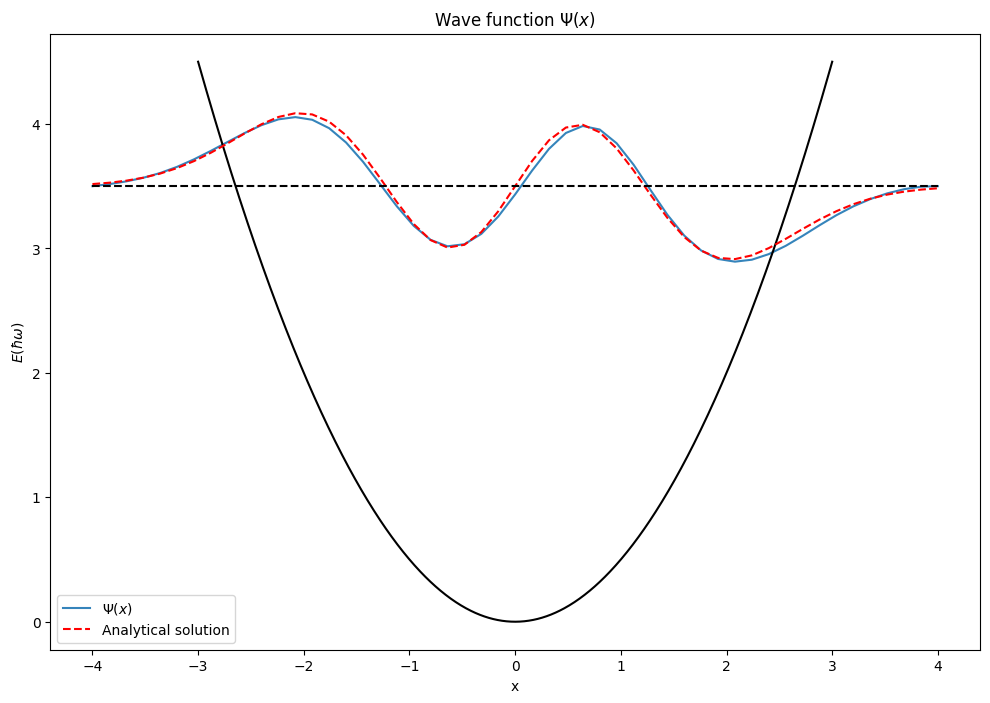

In [44]:
plt.figure(figsize=(12, 8))
plt.plot(X_grid_qho, 3.5+egparesultQHO3.data[-1,0,:-1], '-', label=f'$\Psi(x)$', alpha=0.9)
plt.plot(np.linspace(-3,3, 1000), 0.5*np.linspace(-3,3,1000)**2, 'k-')
plt.plot(X_grid_qho, 3.5+-1*APsi3, 'r--', label='Analytical solution')
plt.plot(np.linspace(-4,4,2), np.linspace(3.5,3.5,2), 'k--')
plt.gca().set_title('Wave function $\Psi(x)$')
plt.xlabel('x')
plt.gca().set_ylabel(r'$E(\hbar \omega)$')
plt.legend();

In [45]:
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot_cell_45(i):
    plt.clf()  # Clear previous plot
    plt.figure(figsize=(20, 12))
    plt.suptitle(f'Generation number {i}')
    
    for inds in range(int(egparesultQHO3.data.shape[1])):
        plt.plot(X_grid_qho, 3.5+egparesultQHO3.data[i,inds,:-1])#, label='Best solutions')

    plt.gca().set_title('Wave function $\Psi(x)$')
    plt.xlabel('x')
    plt.gca().set_ylabel(r'$\Psi(x)$')
    plt.plot(np.linspace(-3,3, 1000), 0.5*np.linspace(-3,3,1000)**2, 'k-')
    plt.plot(np.linspace(-4,4,n_variables), 3.5+-1*APsi3, 'r--', label='Analytical solution')
    plt.plot(np.linspace(-4,4,2), np.linspace(3.5,3.5,2), 'k--')
    plt.legend();

#Create a slider widget
generation_slider_cell_45 = widgets.IntSlider(value=0, min=0, max=len(egparesultQHO3.data)-1, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot_cell_45 function
interact(update_plot_cell_45, i=generation_slider_cell_45);


interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=164), Outp…

In [46]:
import matplotlib.pyplot as plt
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot_cell_46(i):
    plt.clf()  # Clear previous plot
    plt.figure(figsize=(20, 12))
    plt.suptitle(f'Generation number {i}')
    
    


    mean_prediction, std_prediction = egparesultQHO3.GP_hist[i].predict(X_grid_qho, return_std=True)
    plt.plot(X_grid_qho, 3.5+mean_prediction, label="Mean prediction")
    plt.fill_between(
        X_grid_qho.ravel(),
        3.5+ mean_prediction - 1.96 * std_prediction,
        3.5+mean_prediction + 1.96 * std_prediction,
        alpha=0.5,
        label=r"95% confidence interval",
    )

    plt.gca().set_title('Wave function $\Psi(x)$')
    plt.xlabel('x')
    plt.gca().set_ylabel(r'$\Psi(x)$')
    plt.plot(np.linspace(-3,3, 1000), 0.5*np.linspace(-3,3,1000)**2, 'k-')
    plt.plot(np.linspace(-4,4,n_variables), 3.5+-1*APsi3, 'r--', label='Analytical solution')
    plt.plot(np.linspace(-4,4,2), np.linspace(3.5,3.5,2), 'k--')
    plt.legend();

#Create a slider widget
generation_slider_cell_46 = widgets.IntSlider(value=0, min=0, max=len(egparesultQHO3.data)-1, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot_cell_46 function
interact(update_plot_cell_46, i=generation_slider_cell_46);



# mean_prediction, std_prediction = egparesultQHO3.GP_hist[0].predict(X_grid_qho, return_std=True)
# #plt.scatter(X_train, Y_train, label="Observations")
# plt.plot(X_grid_qho, mean_prediction, label="Mean prediction")
# plt.fill_between(
#     X_grid_qho.ravel(),
#     mean_prediction - 1.96 * std_prediction,
#     mean_prediction + 1.96 * std_prediction,
#     alpha=0.5,
#     label=r"95% confidence interval",
# )
# plt.legend()
# plt.xlabel("$x$")
# plt.ylabel("$f(x)$")
# _ = plt.title("Gaussian process regression on noise-free dataset")

interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=164), Outp…

## **Solving Non-Linear Schrödinger Equation**
To solve the Non-Linear Schrödinger Equation we will use an optimization function based on the earlier paper *Applications of Genetic Algorithms to the Solutions of ODEs* by D. A. Diver (1993).

The nonlinear forced harmonic-oscillator problem is a nonlinear ordinary differential equation:

\begin{equation}
\frac{1}{2}y''(x)-\frac{1}{2}y(x)+y(x)^3=0 \quad \tag{1}
\end{equation}

subject to the boundary conditions $y(0)=1$ and $y'(0)=0$.

The analytical solution is $y(x)=\operatorname{sech}(x)$.

Conditions on $y(x)$ are imposed as evidence in the Gaussian process. Conditions on the derivative are imposed in the cost-function definition.

We seek a discretized solution vector
$$
y=[y(x_1),y(x_2),\ldots,y(x_n)].
$$
The cost function is defined in terms of the residuals of candidate solutions in equation (1), using numerical derivatives.

The numerical second derivative is
$$
y''(x) = \frac{d^2y}{dx^2}(x_i)=\frac{y(x_{i-1})+y(x_{i+1})-2y(x_i)}{h^2},
$$
where $h=x_i-x_{i-1}$ is constant for our fixed grid.

The cost function for a candidate solution $y$ is
\begin{equation}
R=\sum_i R_i = \sum_i\left[\frac{1}{2}\left[\frac{y(x_{i-1})+y(x_{i+1})-2y(x_i)}{h^2}\right]-\frac{1}{2}y(x_i)+y(x_i)^3\right].
\end{equation}

Here, $R_i$ are the residuals obtained by applying the numerical derivative definitions to the differential equation at $x_i$. If $y(x)$, represented by the values $y_i=y(x_i)$, is a solution, then $R_i=0$ for every $i$. The value $y'^*$ is a user-defined gradient at a point, used to enforce possible boundary conditions on $y'(x)$.

The derivative-boundary penalty is
\begin{equation}
D=e^{\left|y'(0)-y^{*\prime}(0)\right|}-1.
\end{equation}

Finally, the objective can be written as
$$
Z=R+\alpha D \in [0,\infty),
$$


In [47]:
import sys
import os
# Get the absolute path of the main directory
main_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
# Add the main directory to sys.path
sys.path.append(main_dir)
from OptFunctions.NonLinearSE import *
from EGPA import *
import numpy as np
import warnings
warnings.filterwarnings("ignore")

In [48]:
L=2
n_variables = 51
X_grid_nlse = np.linspace(start=-1, stop=1, num=n_variables).reshape(-1,1) #para que sean n_variables filas y 1 columna
#Ahora definimos las observaciones que hemos hecho de la función. En este caso son las condiciones de contorno del problema
#Los datos que conocemos son las amplitudes en x=0 que son 1
#X_train = X_grid_nlse[n_variables//2]
X_train = np.array((0)).reshape(-1,1)
Y_train = np.linspace(start=1, stop=1, num=1).reshape(-1,1) #Para que sea 2D array
params = {'L':L}

In [49]:
print(r' Analytical solution sech(x) on optimization function:', '\n Non exp problem definition (opt defined at 0) yields:',
NLSE(1/np.cosh(X_grid_nlse[:,0]), L=2, exponential=False), '\n exp problem definition (opt defined at -1) yields:', 
NLSE(1/np.cosh(X_grid_nlse[:,0]), L=2, exponential=True))

 Analytical solution sech(x) on optimization function: 
 Non exp problem definition (opt defined at 0) yields: 3.946398776202425518 
 exp problem definition (opt defined at -1) yields: -0.96130457209627424457


In [50]:
Gaussian = EGPA(size_gen=200, grid_X=X_grid_nlse, max_iter=400, dead_iter=50, alpha=0.03, elite_factor=0.02, init_kernels=8 ,parallelize=True, init_data=(X_train, Y_train), normalize_solutions=False, symmetrize_solutions=False, analysis_mode=True)
egparesultNLSE = Gaussian.minimize(NLSE, params, exp_from = 3000, output_runtime=True)

IT:  0 	Best cost:  4043.243198479869914
IT:  1 	Best cost:  520.82308595425941017
IT:  2 	Best cost:  263.09899445995707773
IT:  3 	Best cost:  197.4355663068416014
IT:  4 	Best cost:  197.4355663068416014
IT:  5 	Best cost:  197.4355663068416014
IT:  6 	Best cost:  197.4355663068416014
IT:  7 	Best cost:  197.4355663068416014
IT:  8 	Best cost:  189.05361072896134117
IT:  9 	Best cost:  189.05361072896134117
IT:  10 	Best cost:  189.05361072896134117
IT:  11 	Best cost:  189.05361072896134117
IT:  12 	Best cost:  189.05361072896134117
IT:  13 	Best cost:  189.05361072896134117
IT:  14 	Best cost:  189.05361072896134117
IT:  15 	Best cost:  189.05361072896134117
IT:  16 	Best cost:  189.05361072896134117
IT:  17 	Best cost:  189.05361072896134117
IT:  18 	Best cost:  189.05361072896134117
IT:  19 	Best cost:  189.05361072896134117
IT:  20 	Best cost:  189.05361072896134117
IT:  21 	Best cost:  189.05361072896134117
IT:  22 	Best cost:  189.05361072896134117
IT:  23 	Best cost:  189.05

In [51]:
egparesultNLSE.best_sampled.shape

(59, 1, 52)

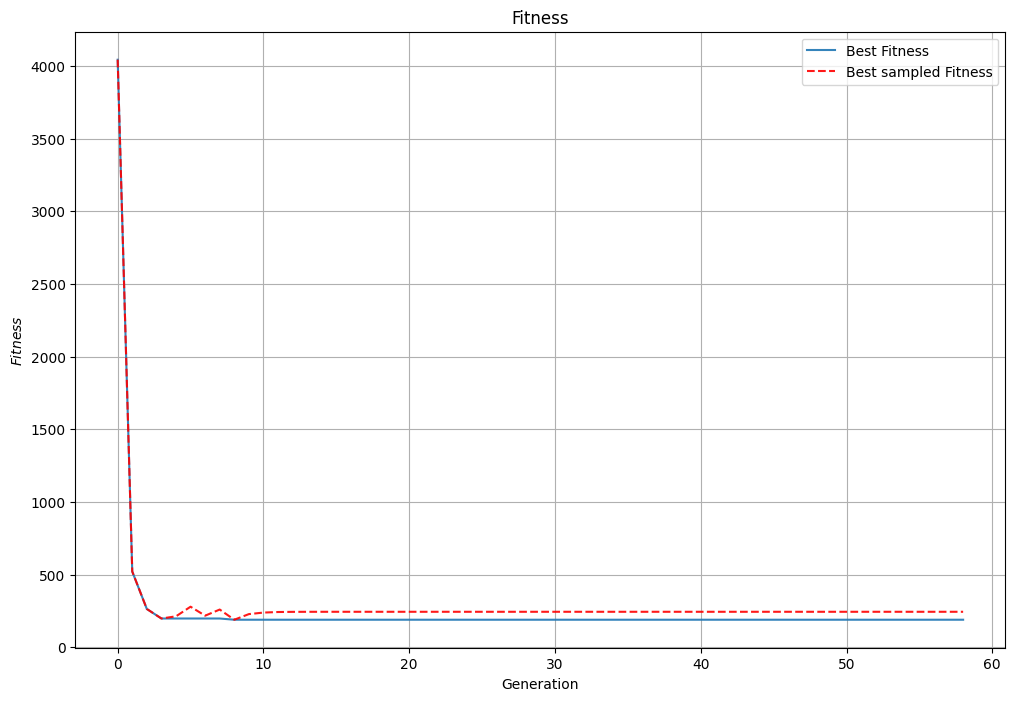

In [52]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 8))

plt.plot(np.arange(0, len(egparesultNLSE.data), 1),egparesultNLSE.data[:,0,-1], '-', label='Best Fitness', alpha=0.9)
plt.plot(np.arange(0, len(egparesultNLSE.data), 1),egparesultNLSE.best_sampled[:, 0, -1], 'r--', label='Best sampled Fitness', alpha=0.9)
# plt.ylim((-1, 0.2))
# plt.xlim((38, 75))
plt.grid()
plt.gca().set_title(r'Fitness')
plt.xlabel('Generation')
plt.gca().set_ylabel(r'$Fitness$')
plt.legend(loc = 'upper right');

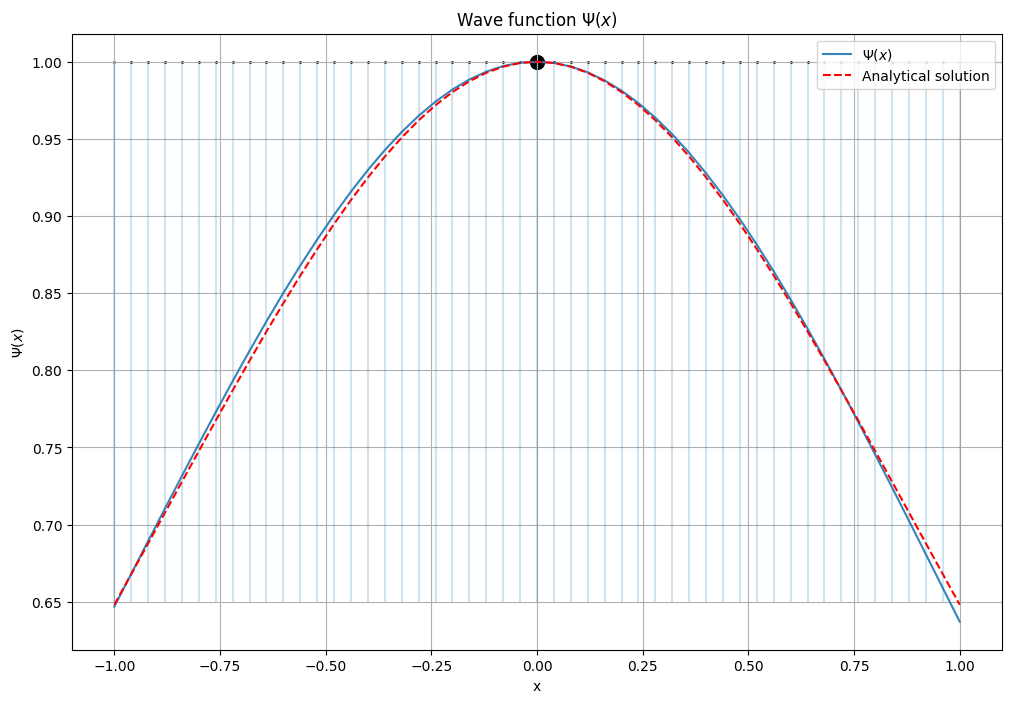

In [53]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 8))

plt.plot(np.linspace(-1, 1, n_variables),egparesultNLSE.data[-1,0,:-1], '-', label='$\Psi(x)$', alpha=0.9)
plt.plot(X_grid_nlse[:, 0], 1/np.cosh(X_grid_nlse[:,0]), 'r--', label='Analytical solution')
plt.scatter(X_grid_nlse[n_variables//2, 0], 1, s=100, c='black')
plt.scatter(X_grid_nlse[:, 0], n_variables*[1], s=1, c='black')
for i in range(len(X_grid_nlse[:, 0])):
    plt.vlines(x=X_grid_nlse[i,0], ymin=0.65, ymax=1, alpha=0.2)
plt.grid()
plt.gca().set_title(r'Wave function $\Psi(x)$')
plt.xlabel('x')
plt.gca().set_ylabel(r'$\Psi(x)$')
plt.legend(loc = 'upper right');

In [54]:
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot_cell_64(i):
    plt.clf()  # Clear previous plot
    plt.figure(figsize=(20, 12))
    plt.suptitle(f'Generation number {i}')
    
    for inds in range(int(len(egparesultNLSE.data[0, :,-1]))):
        plt.plot(X_grid_nlse[:, 0], egparesultNLSE.data[i,inds,:-1])#, label='Best solutions')
    
    plt.plot(X_grid_nlse[:, 0], 1/np.cosh(X_grid_nlse[:,0]), 'r--', label='Analytical solution')
    plt.gca().set_title('Wave function $\Psi(x)$')
    plt.xlabel('x')
    plt.gca().set_ylabel(r'$\Psi(x)$')
    plt.legend();

#Create a slider widget
generation_slider_cell_64 = widgets.IntSlider(value=0, min=0, max=len(egparesultNLSE.data)-1, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot_cell_64 function
interact(update_plot_cell_64, i=generation_slider_cell_64);


interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=58), Outpu…

In [55]:
import matplotlib.pyplot as plt
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot_cell_65(i):
    plt.clf()  # Clear previous plot
    plt.figure(figsize=(20, 12))
    plt.suptitle(f'Generation number {i}')
    
    


    mean_prediction, std_prediction = egparesultNLSE.GP_hist[i].predict(X_grid_nlse, return_std=True)
    plt.plot(X_grid_nlse, mean_prediction, label="Mean prediction")
    plt.fill_between(
        X_grid_nlse.ravel(),
        mean_prediction - 1.96 * std_prediction,
        mean_prediction + 1.96 * std_prediction,
        alpha=0.5,
        label=r"95% confidence interval",
    )

    plt.gca().set_title('Wave function $\Psi(x)$')
    plt.xlabel('x')
    plt.gca().set_ylabel(r'$\Psi(x)$')
    plt.plot(X_grid_nlse[:, 0], 1/np.cosh(X_grid_nlse[:,0]), 'r--', label='Analytical solution')
    plt.legend();

#Create a slider widget
generation_slider_cell_65 = widgets.IntSlider(value=0, min=0, max=len(egparesultNLSE.data)-2, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot_cell_65 function
interact(update_plot_cell_65, i=generation_slider_cell_65);

interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=57), Outpu…